In [4]:
import pandas as pd

df = pd.read_csv("olist_order_reviews_dataset.csv")
df.head()


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [5]:
# 1. Ficar só com as colunas que importam
df = df[["review_score", "review_comment_message"]]
print("Total de avaliações:", len(df))

# 2. Remover avaliações sem texto
df = df.dropna().copy()
print("Avaliações com texto:", len(df))

# 3. Remover as neutras (nota 3)
df = df[df["review_score"] != 3].copy()

# 4. Criar o gabarito: 1 = positivo (nota 4 ou 5), 0 = negativo (nota 1 ou 2)
df["sentimento"] = (df["review_score"] >= 4).astype(int)

print(df["sentimento"].value_counts())
df.head()

Total de avaliações: 99224
Avaliações com texto: 40977
sentimento
1    26530
0    10890
Name: count, dtype: int64


,review_score,review_comment_message,sentimento
3,5,Recebi bem antes do prazo estipulado.,1
4,5,Parabéns lojas lannister adorei comprar pela I...,1
9,4,aparelho eficiente. no site a marca do aparelh...,1
12,4,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",1
15,5,"Vendedor confiável, produto ok e entrega antes...",1


In [6]:
import re

def limpar(texto):
    texto = texto.lower()
    texto = re.sub(r"[^a-záàâãéêíóôõúç\s]", " ", texto)
    texto = re.sub(r"\s+", " ", texto).strip()
    return texto

df["texto"] = df["review_comment_message"].apply(limpar)

# Comparar antes e depois
for i in range(3):
    print("ANTES: ", df["review_comment_message"].iloc[i])
    print("DEPOIS:", df["texto"].iloc[i])
    print()

ANTES:  Recebi bem antes do prazo estipulado.
DEPOIS: recebi bem antes do prazo estipulado

ANTES:  Parabéns lojas lannister adorei comprar pela Internet seguro e prático Parabéns a todos feliz Páscoa
DEPOIS: parabéns lojas lannister adorei comprar pela internet seguro e prático parabéns a todos feliz páscoa

ANTES:  aparelho eficiente. no site a marca do aparelho esta impresso como 3desinfector e ao chegar esta com outro nome...atualizar com a marca correta uma vez que é o mesmo aparelho
DEPOIS: aparelho eficiente no site a marca do aparelho esta impresso como desinfector e ao chegar esta com outro nome atualizar com a marca correta uma vez que é o mesmo aparelho



In [7]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

# 4.1 Separar treino (80%) e teste (20%)
X_train, X_test, y_train, y_test = train_test_split(
    df["texto"], df["sentimento"],
    test_size=0.2, random_state=42, stratify=df["sentimento"]
)
print("Treino:", len(X_train), "| Teste:", len(X_test))

# 4.2 Transformar texto em números (TF-IDF)
vetorizador = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_features=50000)
Xtr = vetorizador.fit_transform(X_train)
Xte = vetorizador.transform(X_test)
print("Formato da matriz de treino:", Xtr.shape)

# 4.3 Treinar o modelo
modelo = LogisticRegression(max_iter=1000, class_weight="balanced")
modelo.fit(Xtr, y_train)
print("Modelo treinado!")

Treino: 29936 | Teste: 7484
Formato da matriz de treino: (29936, 17184)
Modelo treinado!


              precision    recall  f1-score   support

    negativo       0.82      0.95      0.88      2178
    positivo       0.98      0.92      0.94      5306

    accuracy                           0.92      7484
   macro avg       0.90      0.93      0.91      7484
weighted avg       0.93      0.92      0.93      7484



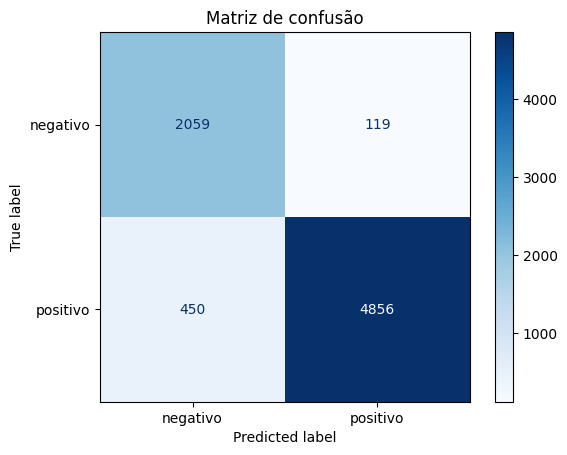

In [8]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Previsões nas avaliações de teste
pred = modelo.predict(Xte)

# Métricas por classe
print(classification_report(y_test, pred, target_names=["negativo", "positivo"]))

# Matriz de confusão
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=["negativo", "positivo"], cmap="Blues"
)
plt.title("Matriz de confusão")
plt.savefig("matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()


Termos mais NEGATIVOS: ['não', 'nao', 'comprei', 'não recomendo', 'nem', 'péssima', 'ruim', 'diferente', 'não recebi', 'péssimo', 'quero', 'demora', 'veio', 'aguardando', 'não gostei']
Termos mais POSITIVOS: ['excelente', 'ótimo', 'tudo', 'recomendo', 'antes', 'rápido', 'adorei', 'amei', 'perfeito', 'parabéns', 'lindo', 'rápida', 'bem', 'antes do', 'no prazo']


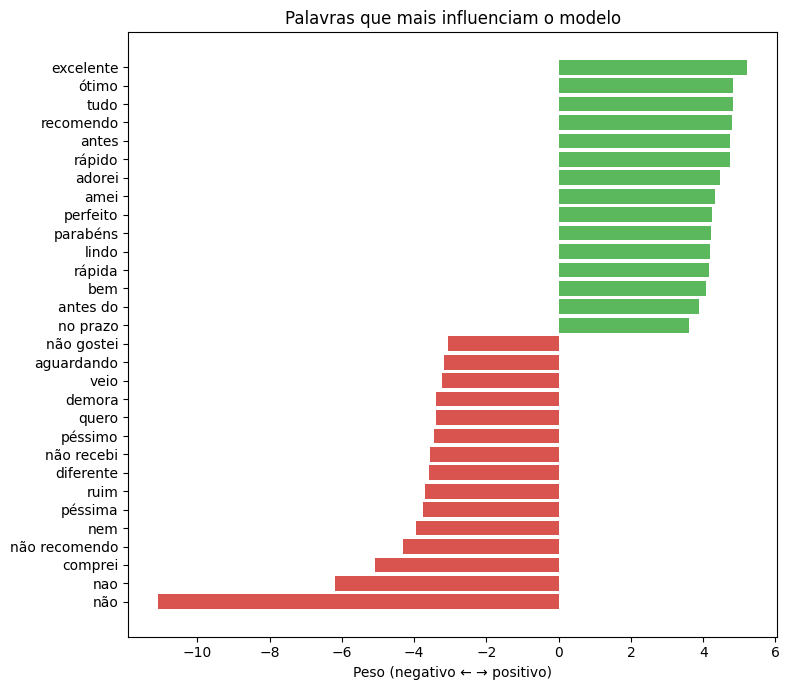

positivo -> Produto chegou rápido e é ótimo, recomendo!
negativo -> Demorou demais e veio quebrado, péssimo atendimento.
negativo -> Não recomendo, não gostei nada.


In [9]:
import numpy as np

nomes = vetorizador.get_feature_names_out()
coef = modelo.coef_[0]
ordem = np.argsort(coef)

top_neg = ordem[:15]    # pesos mais negativos
top_pos = ordem[-15:]   # pesos mais positivos

print("Termos mais NEGATIVOS:", list(nomes[top_neg]))
print("Termos mais POSITIVOS:", list(nomes[top_pos][::-1]))

# Gráfico
idx = np.concatenate([top_neg, top_pos])
cores = ["#d9534f"] * 15 + ["#5cb85c"] * 15

plt.figure(figsize=(8, 7))
plt.barh(nomes[idx], coef[idx], color=cores)
plt.title("Palavras que mais influenciam o modelo")
plt.xlabel("Peso (negativo ← → positivo)")
plt.tight_layout()
plt.savefig("palavras_influentes.png", dpi=150)
plt.show()

# Teste com frases suas
frases = [
    "Produto chegou rápido e é ótimo, recomendo!",
    "Demorou demais e veio quebrado, péssimo atendimento.",
    "Não recomendo, não gostei nada.",
]
for f in frases:
    p = modelo.predict(vetorizador.transform([limpar(f)]))[0]
    print("positivo" if p == 1 else "negativo", "->", f)

In [10]:
import joblib
from google.colab import files

# Salvar vetorizador + modelo juntos
joblib.dump((vetorizador, modelo), "modelo_sentimento.joblib")

# Baixar os arquivos para o seu computador
for arquivo in ["matriz_confusao.png", "palavras_influentes.png", "modelo_sentimento.joblib"]:
    files.download(arquivo)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>